# Electricity consumption analysis

2019–2023: distributions, trend and seasonality. 2024 is excluded. All plots use average load in MW.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'pyproject.toml').exists() and (p / 'data').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Run from inside the electricity-reg-germany repository.')

TARGET = 'Netzlast [MWh] Berechnete Auflösungen'
TIMEZONE = 'Europe/Berlin'
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.2})

## Phase 1 — Prepare the data

- Read hourly and daily CSVs; keep 2019–2023.
- Parse German numbers and localize timestamps to Europe/Berlin.
- Add year, month, hour, weekday and weekend labels.
- Average load (MW) = consumption (MWh) / actual hours: 1 hourly; 23, 24 or 25 daily.

In [2]:
analysis = {}
for resolution, suffix in [('hourly', 'Stunde'), ('daily', 'Tag')]:
    path = ROOT / 'data' / (
        f'Realisierter_Stromverbrauch_201901010000_202501010000_{suffix}.csv')
    raw = pd.read_csv(path, sep=';', encoding='utf-8-sig', dtype=str)
    fmt = '%d.%m.%Y %H:%M' if resolution == 'hourly' else '%d.%m.%Y'
    local = pd.to_datetime(raw['Datum von'], format=fmt, errors='raise')
    selected = (local >= '2019-01-01') & (local < '2024-01-01')
    local = local.loc[selected]
    values = raw.loc[selected, TARGET].str.strip().str.replace('.', '', regex=False)
    values = pd.to_numeric(values.str.replace(',', '.', regex=False), errors='raise')
    if not np.isfinite(values).all() or values.le(0).any():
        raise ValueError(f'{resolution}: investigate invalid consumption before continuing.')
    aware = pd.DatetimeIndex(local).tz_localize(
        TIMEZONE, ambiguous='infer', nonexistent='raise')
    frame = pd.DataFrame({'start_local': aware, 'consumption_mwh': values.to_numpy()})
    local_dates = aware.tz_localize(None).normalize()
    frame['local_date'] = local_dates
    frame['year'] = aware.year
    frame['month'] = aware.month
    frame['hour'] = aware.hour
    frame['weekday'] = aware.day_of_week
    frame['day_type'] = np.where(frame['weekday'] < 5, 'Weekday', 'Weekend')
    if resolution == 'daily':
        next_midnight = (local_dates + pd.Timedelta(days=1)).tz_localize(TIMEZONE)
        frame['interval_hours'] = (next_midnight - aware).total_seconds() / 3600
    else:
        frame['interval_hours'] = 1.0
    frame['average_load_mw'] = frame['consumption_mwh'] / frame['interval_hours']
    analysis[resolution] = frame
    print(f'{resolution}: {len(frame):,} observations, {local.min()} to {local.max()}')
    display(analysis[resolution].head(7))
hourly, daily = analysis['hourly'], analysis['daily']

hourly: 43,824 observations, 2019-01-01 00:00:00 to 2023-12-31 23:00:00


,start_local,consumption_mwh,local_date,year,month,hour,weekday,day_type,interval_hours,average_load_mw
0,2019-01-01 00:00:00+01:00,43273.75,2019-01-01,2019,1,0,1,Weekday,1.0,43273.75
1,2019-01-01 01:00:00+01:00,41631.25,2019-01-01,2019,1,1,1,Weekday,1.0,41631.25
2,2019-01-01 02:00:00+01:00,40085.00,2019-01-01,2019,1,2,1,Weekday,1.0,40085.00
3,2019-01-01 03:00:00+01:00,39269.75,2019-01-01,2019,1,3,1,Weekday,1.0,39269.75
4,2019-01-01 04:00:00+01:00,39032.75,2019-01-01,2019,1,4,1,Weekday,1.0,39032.75
5,2019-01-01 05:00:00+01:00,38570.50,2019-01-01,2019,1,5,1,Weekday,1.0,38570.50
6,2019-01-01 06:00:00+01:00,38047.50,2019-01-01,2019,1,6,1,Weekday,1.0,38047.50


daily: 1,826 observations, 2019-01-01 00:00:00 to 2023-12-31 00:00:00


,start_local,consumption_mwh,local_date,year,month,hour,weekday,day_type,interval_hours,average_load_mw
0,2019-01-01 00:00:00+01:00,1097118.75,2019-01-01,2019,1,0,1,Weekday,24.0,45713.281250
1,2019-01-02 00:00:00+01:00,1388494.25,2019-01-02,2019,1,0,2,Weekday,24.0,57853.927083
2,2019-01-03 00:00:00+01:00,1466308.25,2019-01-03,2019,1,0,3,Weekday,24.0,61096.177083
3,2019-01-04 00:00:00+01:00,1486876.25,2019-01-04,2019,1,0,4,Weekday,24.0,61953.177083
4,2019-01-05 00:00:00+01:00,1315755.00,2019-01-05,2019,1,0,5,Weekend,24.0,54823.125000
5,2019-01-06 00:00:00+01:00,1207037.75,2019-01-06,2019,1,0,6,Weekend,24.0,50293.239583
6,2019-01-07 00:00:00+01:00,1525289.00,2019-01-07,2019,1,0,0,Weekday,24.0,63553.708333


## Phase 2 — Distributions

Boxplots compare average load by hour, weekday/weekend, weekday, month and year.

- Middle line: median. Box: middle 50% of values.
- Dots: values outside the whiskers; not confirmed errors.
- The last line plot compares weekday and weekend median hourly profiles.

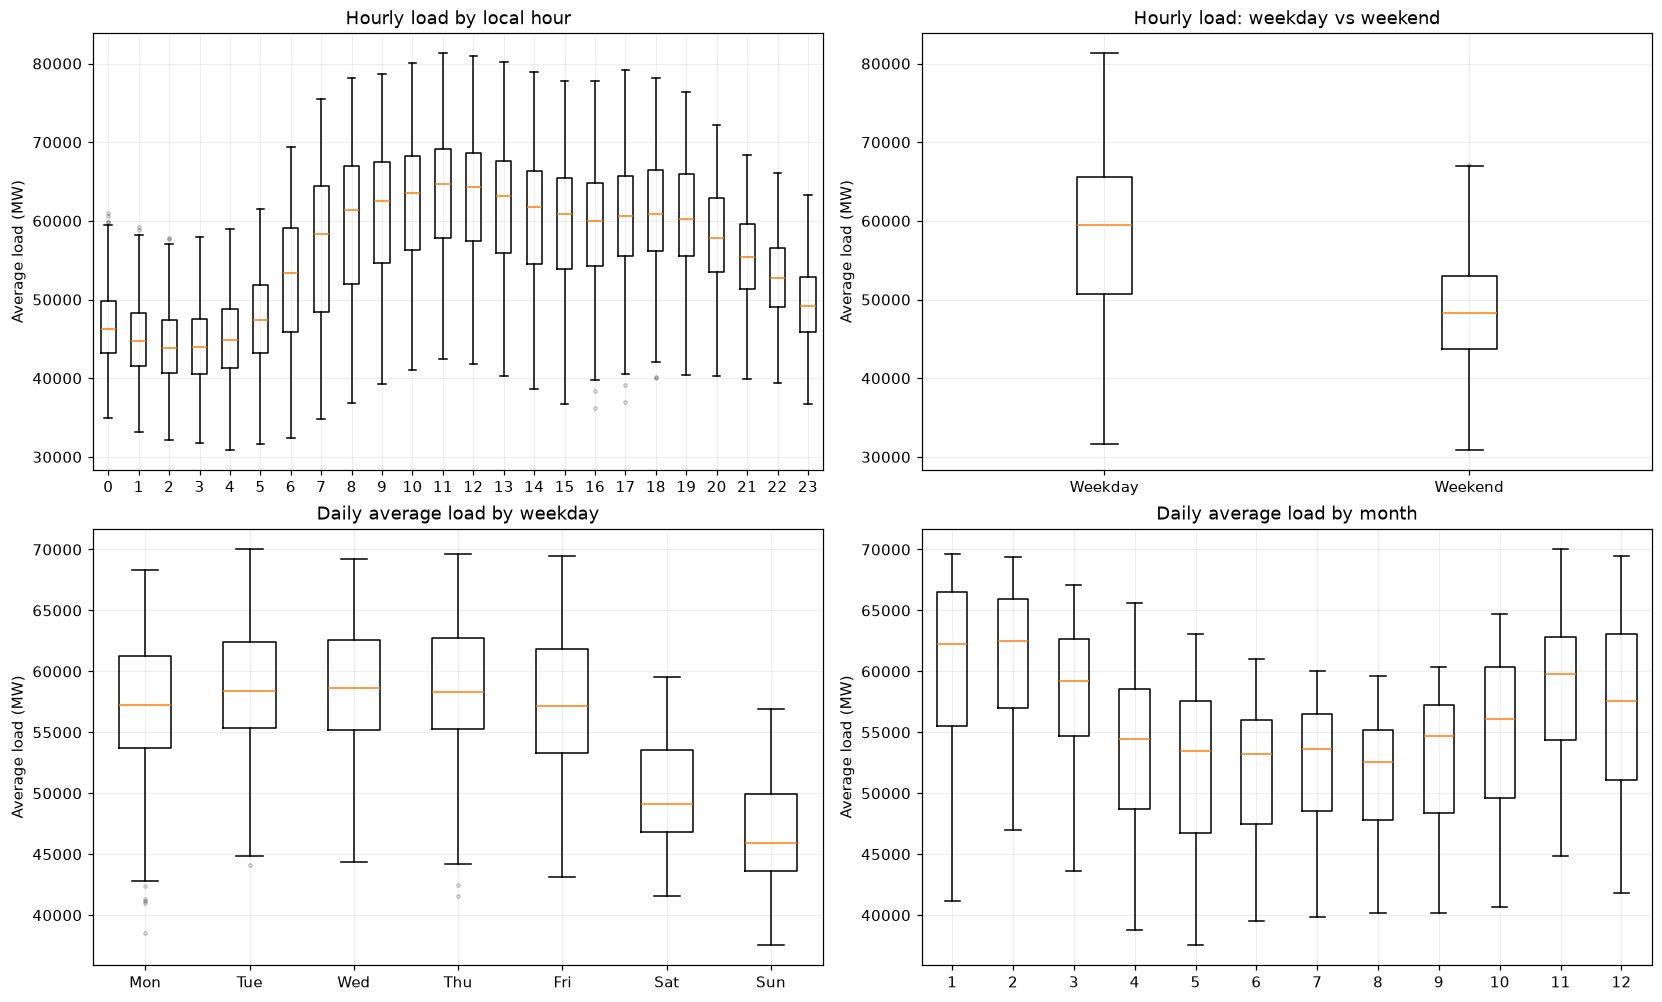

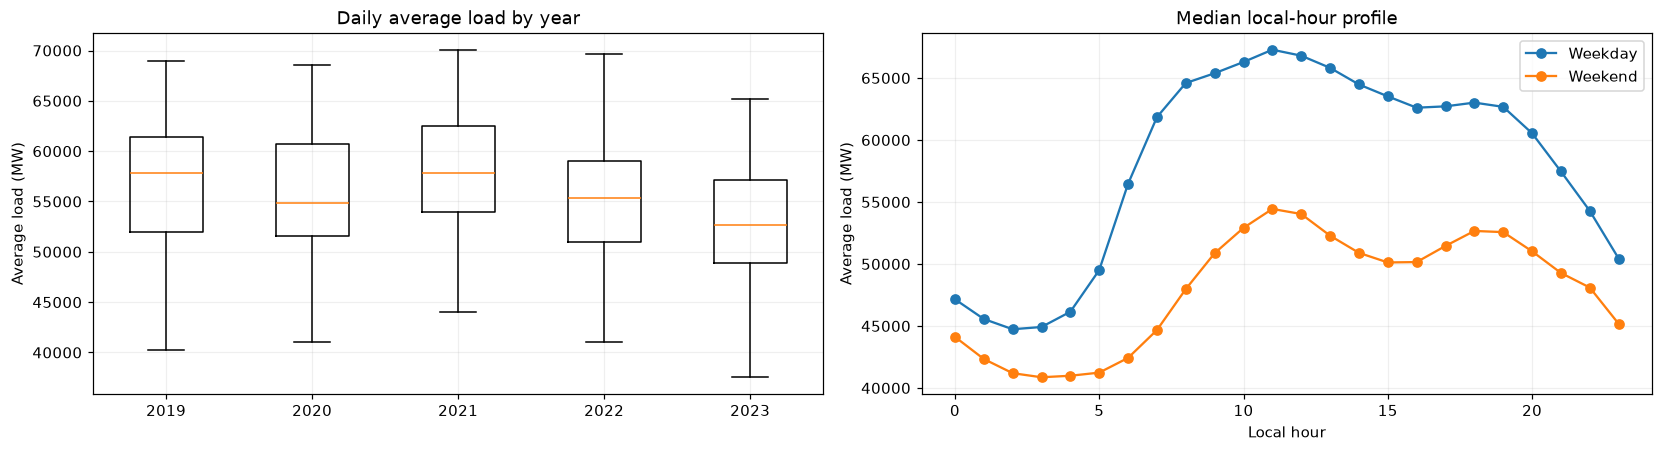

In [3]:
def calendar_boxplot(ax, frame, group, order, labels, title):
    samples = [frame.loc[frame[group].eq(value), 'average_load_mw'].to_numpy()
               for value in order]
    ax.boxplot(samples, tick_labels=labels, showfliers=True,
               flierprops={'markersize': 2, 'alpha': 0.25})
    ax.set(title=title, ylabel='Average load (MW)')

fig, axes = plt.subplots(2, 2, figsize=(15, 9), constrained_layout=True)
calendar_boxplot(axes[0, 0], hourly, 'hour', range(24), range(24), 'Hourly load by local hour')
calendar_boxplot(axes[0, 1], hourly, 'day_type', ['Weekday', 'Weekend'],
                 ['Weekday', 'Weekend'], 'Hourly load: weekday vs weekend')
calendar_boxplot(axes[1, 0], daily, 'weekday', range(7),
                 ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'], 'Daily average load by weekday')
calendar_boxplot(axes[1, 1], daily, 'month', range(1, 13), range(1, 13),
                 'Daily average load by month')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 4), constrained_layout=True)
calendar_boxplot(axes[0], daily, 'year', range(2019, 2024), range(2019, 2024),
                 'Daily average load by year')
for kind, group in hourly.groupby('day_type'):
    axes[1].plot(group.groupby('hour')['average_load_mw'].median(), marker='o', label=kind)
axes[1].set(title='Median local-hour profile', xlabel='Local hour', ylabel='Average load (MW)')
axes[1].legend()
plt.show()

## Phase 3 — Trend

- Gray: observed daily average load.
- Blue: centered 31-day mean; red: centered 91-day mean.
- Second plot: monthly mean of daily average load.
- Table: yearly averages and change from the previous year.

Rolling means reduce short-term fluctuations but still contain annual seasonality. Centered windows use past and future observations; this is descriptive analysis.

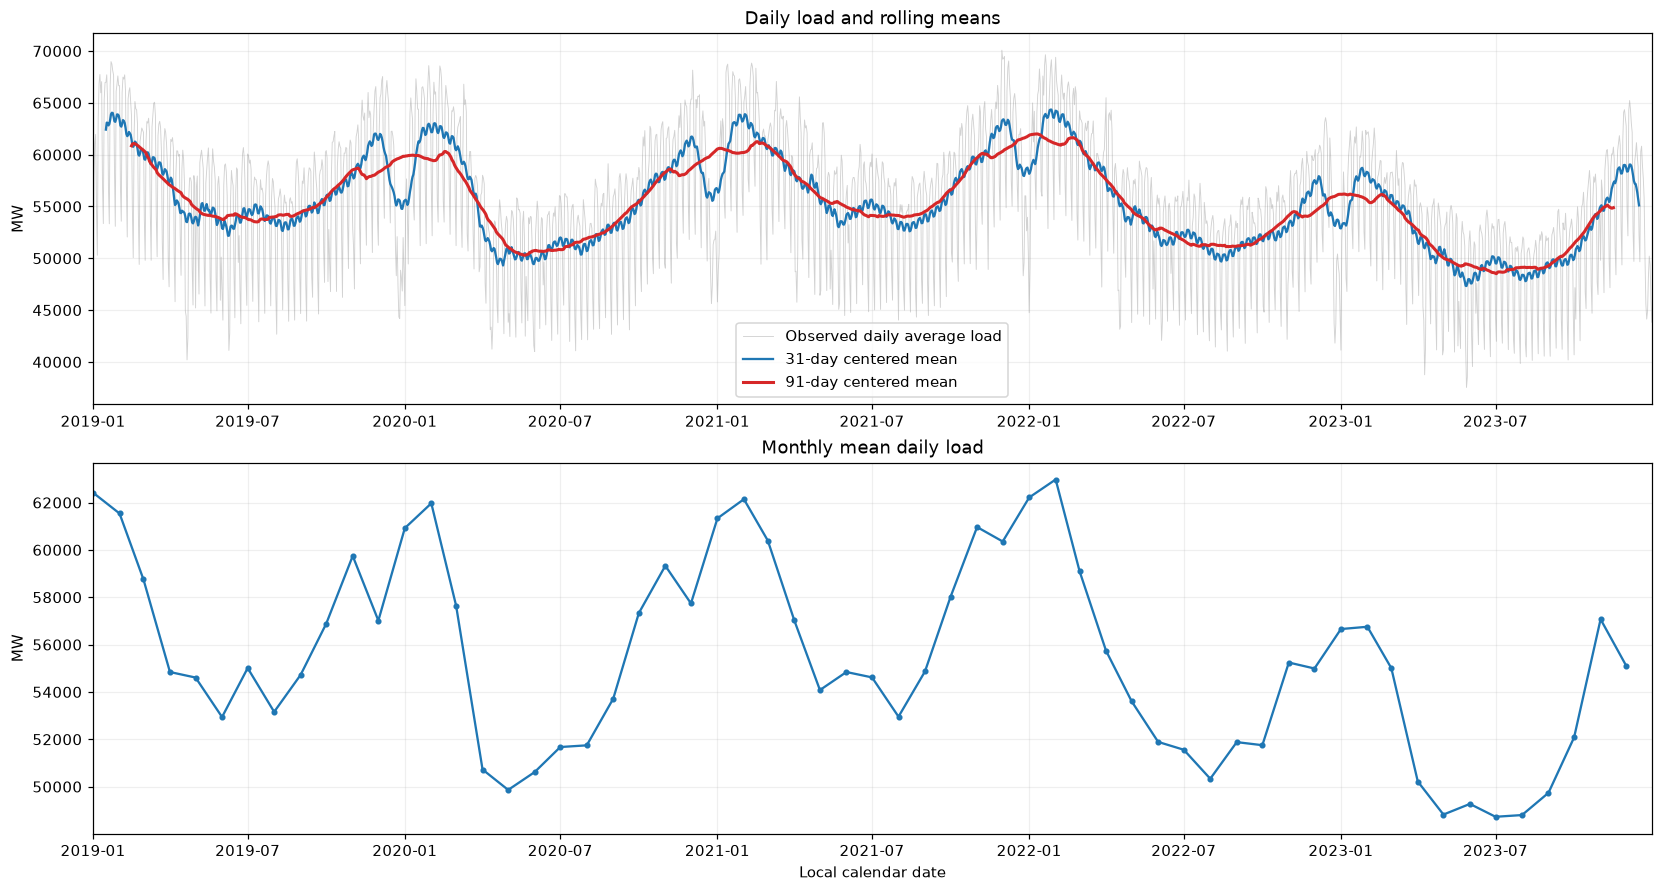

,days,mean_daily_load_mw,median_daily_load_mw,mean_change_vs_previous_year_percent
year,,,,
2019,365,56776.92,57838.02,NaN
2020,366,55254.67,54882.48,-2.68
2021,365,57603.10,57801.35,4.25
2022,365,55057.19,55311.33,-4.42
2023,365,52326.58,52642.18,-4.96


In [4]:
daily_load = pd.Series(
    daily['average_load_mw'].to_numpy(),
    index=pd.DatetimeIndex(daily['local_date']),
    name='daily_average_load_mw',
).sort_index()
expected_dates = pd.date_range('2019-01-01', '2023-12-31', freq='D')
if not daily_load.index.equals(expected_dates) or not np.isfinite(daily_load).all():
    raise ValueError('Trend analysis requires complete, ordered local daily observations.')
daily_load = daily_load.asfreq('D')
trend_smoothers = pd.DataFrame({'observed_mw': daily_load})
trend_smoothers['rolling_31_days_mw'] = daily_load.rolling(31, center=True).mean()
trend_smoothers['rolling_91_days_mw'] = daily_load.rolling(91, center=True).mean()
monthly_average_load = daily_load.resample('MS').mean()

fig, axes = plt.subplots(2, 1, figsize=(15, 8), constrained_layout=True)
axes[0].plot(daily_load.index, daily_load, color='gray', alpha=0.35,
             linewidth=0.6, label='Observed daily average load')
axes[0].plot(trend_smoothers.index, trend_smoothers.rolling_31_days_mw,
             label='31-day centered mean', color='tab:blue')
axes[0].plot(trend_smoothers.index, trend_smoothers.rolling_91_days_mw,
             label='91-day centered mean', color='tab:red', linewidth=2)
axes[0].set(title='Daily load and rolling means', ylabel='MW')
axes[0].legend()
axes[1].plot(monthly_average_load.index, monthly_average_load, marker='o', markersize=3)
axes[1].set(title='Monthly mean daily load',
            xlabel='Local calendar date', ylabel='MW')
for ax in axes:
    ax.set_xlim(daily_load.index.min(), daily_load.index.max())
plt.show()

yearly_load_summary = daily.groupby('year').agg(
    days=('average_load_mw', 'size'),
    mean_daily_load_mw=('average_load_mw', 'mean'),
    median_daily_load_mw=('average_load_mw', 'median'),
)
yearly_load_summary['mean_change_vs_previous_year_percent'] = (
    yearly_load_summary['mean_daily_load_mw'].pct_change() * 100
)
display(yearly_load_summary.round(2))

## Phase 4 — Seasonality

| Plot | Calculation |
|---|---|
| Hourly profile | Mean load at each local hour, split by weekday/weekend |
| Weekly profile | Mean daily load by weekday, separately for each year |
| Annual profile | Monthly mean daily load minus that year's mean |
| Heatmap | Mean hourly load for each weekday/hour combination |

The annual plot compares seasonal shape after removing each year's average level. Holidays and weather are not accounted for.

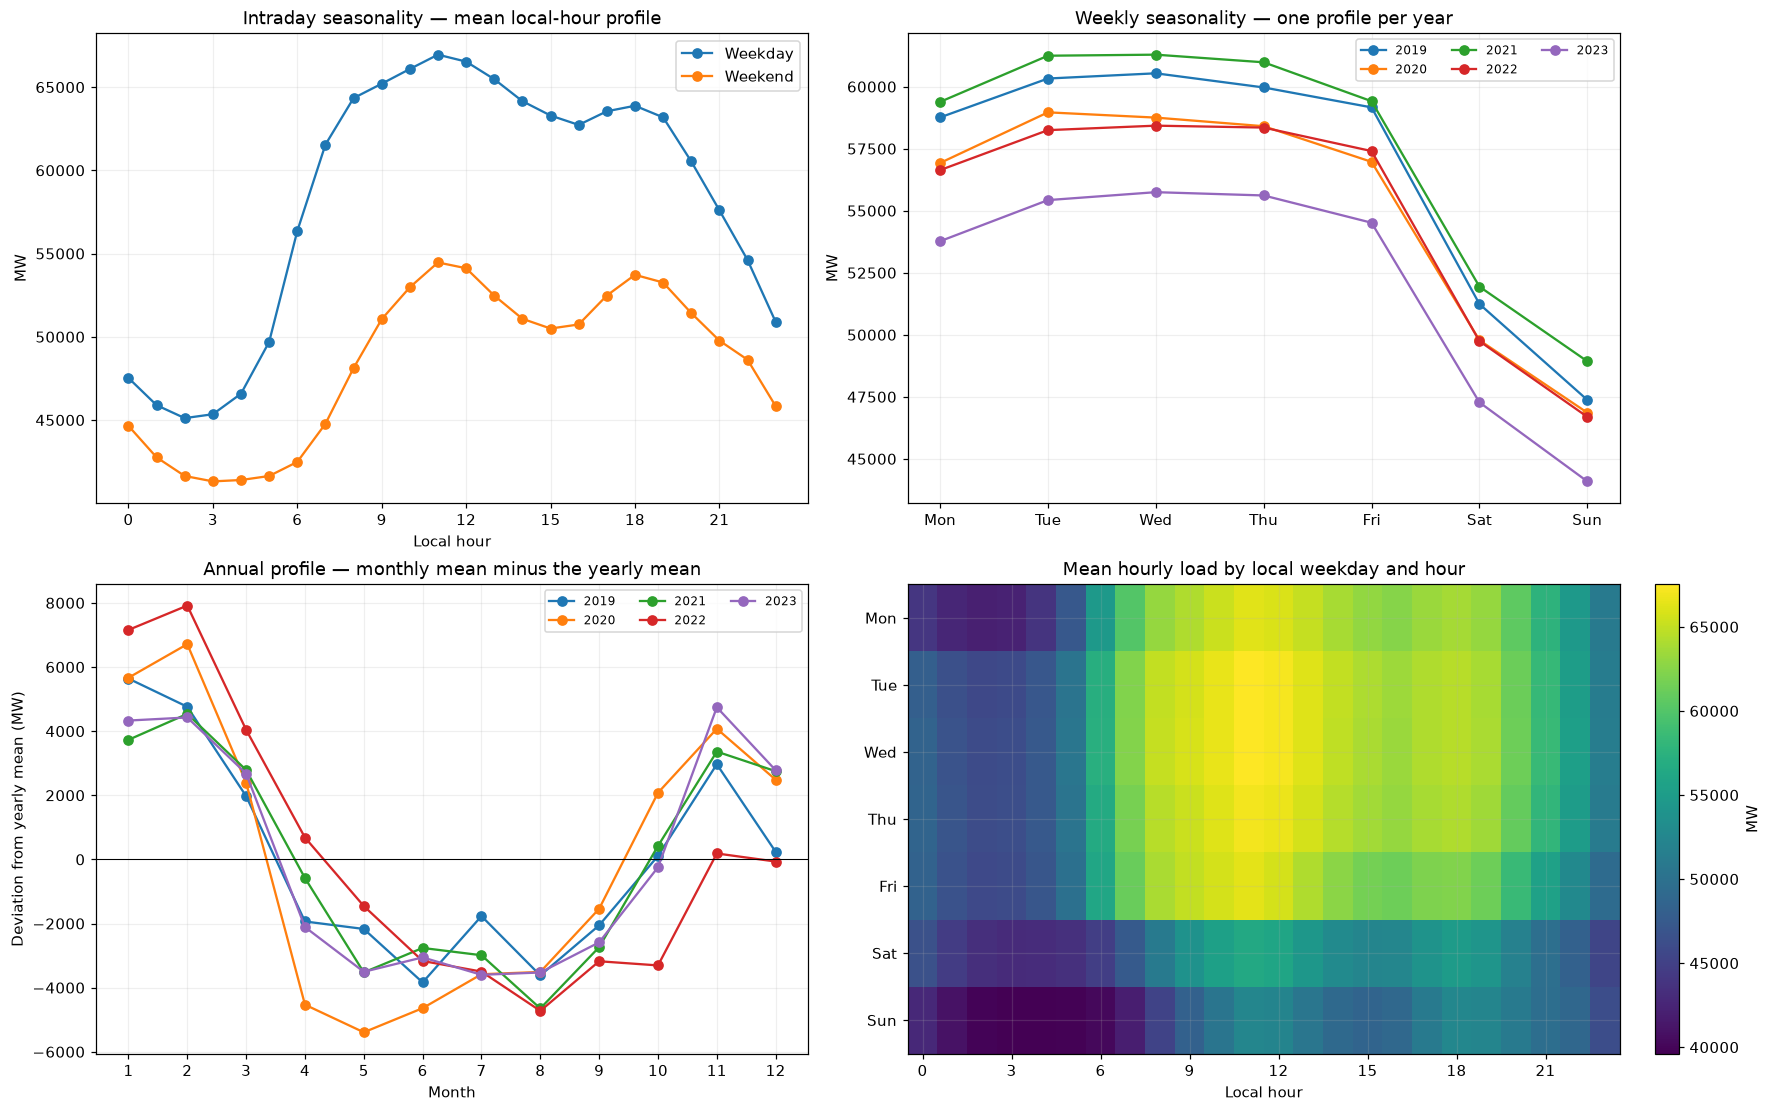

In [5]:
weekday_labels = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
fig, axes = plt.subplots(2, 2, figsize=(16, 10), constrained_layout=True)
for kind, group in hourly.groupby('day_type'):
    profile = group.groupby('hour')['average_load_mw'].mean()
    axes[0, 0].plot(profile.index, profile, marker='o', label=kind)
axes[0, 0].set(title='Intraday seasonality — mean local-hour profile',
               xlabel='Local hour', ylabel='MW', xticks=range(0, 24, 3))
axes[0, 0].legend()

for year, group in daily.groupby('year'):
    weekly_profile = group.groupby('weekday')['average_load_mw'].mean()
    axes[0, 1].plot(weekly_profile.index, weekly_profile, marker='o', label=str(year))
    monthly_profile = group.groupby('month')['average_load_mw'].mean()
    axes[1, 0].plot(monthly_profile.index,
                    monthly_profile - group['average_load_mw'].mean(),
                    marker='o', label=str(year))
axes[0, 1].set(title='Weekly seasonality — one profile per year', ylabel='MW',
               xticks=range(7), xticklabels=weekday_labels)
axes[0, 1].legend(ncol=3, fontsize=8)
axes[1, 0].axhline(0, color='black', linewidth=0.7)
axes[1, 0].set(title='Annual profile — monthly mean minus the yearly mean',
               xlabel='Month', ylabel='Deviation from yearly mean (MW)', xticks=range(1, 13))
axes[1, 0].legend(ncol=3, fontsize=8)

hour_weekday_profile = hourly.pivot_table(
    index='weekday', columns='hour', values='average_load_mw', aggfunc='mean',
).reindex(index=range(7), columns=range(24))
heatmap = axes[1, 1].imshow(hour_weekday_profile, aspect='auto', cmap='viridis')
axes[1, 1].set(title='Mean hourly load by local weekday and hour',
               xlabel='Local hour', xticks=range(0, 24, 3),
               yticks=range(7), yticklabels=weekday_labels)
fig.colorbar(heatmap, ax=axes[1, 1], label='MW')
plt.show()

## Phase 5 — Decomposition

`Observed daily load = trend + weekly seasonality + annual seasonality + remainder`

MSTL uses periods of 7 and 365 days. Robust fitting reduces the influence of extremes without removing observations.

- Weekly plot: first eight weeks of 2023. Other plots: 2019–2023.
- Annual cycle is approximate: leap years and moving holidays are not explicitly modeled.
- Remainder: variation not explained by the components; not necessarily data errors.
- This is retrospective analysis, not a forecasting model. Edge estimates are less reliable.

Component sum matches observed load.


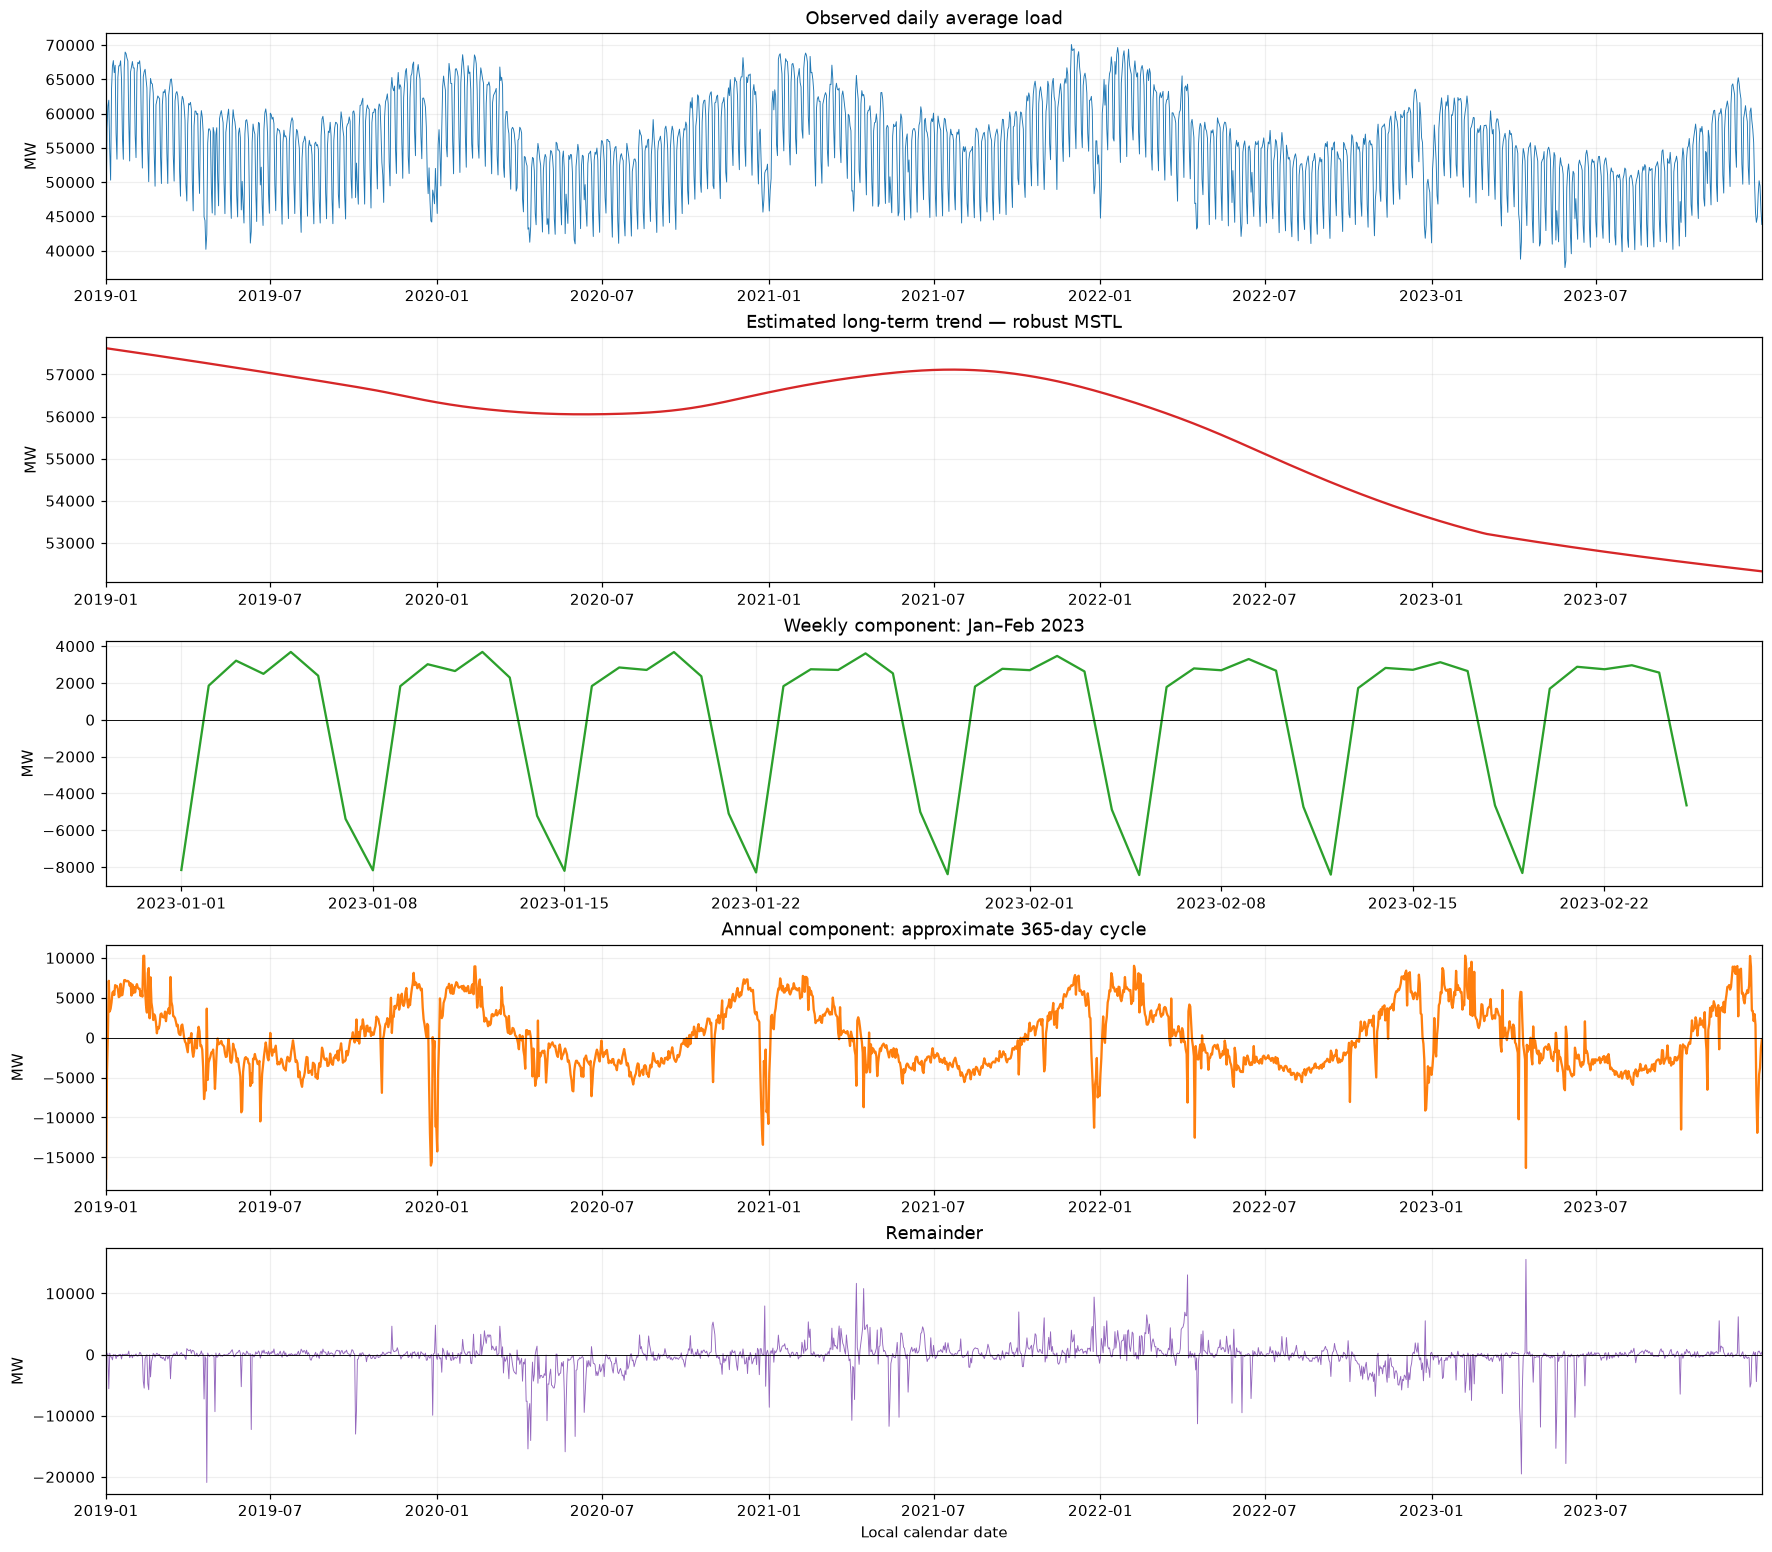

,mean_observed_mw,mean_trend_mw,remainder_std_mw
year,,,
2019,56776.92,57016.60,1921.76
2020,55254.67,56184.59,2573.83
2021,57603.10,56924.64,2201.44
2022,55057.19,55099.56,2393.69
2023,52326.58,52848.73,2498.83


In [6]:
from statsmodels.tsa.seasonal import MSTL

seasonal_fit = MSTL(daily_load, periods=(7, 365), stl_kwargs={'robust': True}).fit()
seasonal_components = seasonal_fit.seasonal
if not isinstance(seasonal_components, pd.DataFrame) or seasonal_components.shape[1] != 2:
    raise ValueError('Expected both weekly and annual seasonal components.')
decomposition = pd.DataFrame({
    'observed_mw': daily_load,
    'trend_mw': seasonal_fit.trend,
    'weekly_mw': seasonal_components.iloc[:, 0],
    'annual_mw': seasonal_components.iloc[:, 1],
    'remainder_mw': seasonal_fit.resid,
})
reconstructed_load = decomposition[
    ['trend_mw', 'weekly_mw', 'annual_mw', 'remainder_mw']
].sum(axis=1)
np.testing.assert_allclose(reconstructed_load, daily_load, rtol=1e-10, atol=1e-8)
print('Component sum matches observed load.')

fig, axes = plt.subplots(5, 1, figsize=(16, 14), constrained_layout=True)
axes[0].plot(decomposition.index, decomposition.observed_mw, linewidth=0.6)
axes[0].set(title='Observed daily average load', ylabel='MW')
axes[1].plot(decomposition.index, decomposition.trend_mw, color='tab:red')
axes[1].set(title='Estimated long-term trend — robust MSTL', ylabel='MW')
weekly_zoom = decomposition.loc['2023-01-01':'2023-02-25', 'weekly_mw']
axes[2].plot(weekly_zoom.index, weekly_zoom, color='tab:green')
axes[2].set(title='Weekly component: Jan–Feb 2023', ylabel='MW')
axes[3].plot(decomposition.index, decomposition.annual_mw, color='tab:orange')
axes[3].set(title='Annual component: approximate 365-day cycle', ylabel='MW')
axes[4].plot(decomposition.index, decomposition.remainder_mw, linewidth=0.6, color='tab:purple')
axes[4].set(title='Remainder',
            xlabel='Local calendar date', ylabel='MW')
for ax in axes[2:]:
    ax.axhline(0, color='black', linewidth=0.6)
for ax in [axes[0], axes[1], axes[3], axes[4]]:
    ax.set_xlim(daily_load.index.min(), daily_load.index.max())
plt.show()

decomposition_yearly = decomposition.assign(year=decomposition.index.year).groupby('year').agg(
    mean_observed_mw=('observed_mw', 'mean'),
    mean_trend_mw=('trend_mw', 'mean'),
    remainder_std_mw=('remainder_mw', 'std'),
)
display(decomposition_yearly.round(2))

### Findings

- Load is lower overnight and on weekends; higher on weekday daytime hours.
- Winter months generally have higher relative load than summer months.
- Mean daily load: 56,777 MW in 2019 and 52,327 MW in 2023, with a rebound in 2021.
- Year-on-year change: −4.42% in 2022 and −4.96% in 2023.
- MSTL estimates a declining trend after 2021. Causes have not been established.